### 实验2 神经网络应用案例与调优（2 新闻多分类）

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入第三方库

In [1]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

In [2]:
from pathlib import Path
import json
import time
from datetime import datetime
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from torch.utils.tensorboard import SummaryWriter
torch.set_num_threads(2)

（2）设置图表显示

In [ ]:
# 显式启用Notebook内嵌绘图，批量运行时也保留图表输出
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便使用GPU

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [5]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

In [ ]:
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# 每次从头运行写入独立目录，防止多次训练的事件互相混合
LOG_DIR = OUTPUT_DIR / 'tensorboard' / datetime.now().strftime('%Y%m%d-%H%M%S')
N_CLASSES = 46

##### 1.2 数据导入与预处理
（1）导入Reuters数据并观察形状

In [7]:
def load_reuters(num_words=10000):
    cache = Path.home() / '.keras/datasets/reuters.npz'
    if not cache.exists():
        from keras.datasets import reuters  # 仅允许在导入自带数据集时使用Keras
        return reuters.load_data(num_words=num_words)
    with np.load(cache, allow_pickle=True) as data:
        sequences, labels = data['x'], data['y']
    # 与Keras默认seed=113、start_char=1、index_from=3、oov_char=2保持一致。
    rng = np.random.RandomState(113)
    order = np.arange(len(sequences))
    rng.shuffle(order)
    sequences, labels = sequences[order], labels[order]
    sequences = [[1] + [int(w) + 3 for w in seq] for seq in sequences]
    sequences = np.array([[w if 0 <= w < num_words else 2 for w in seq]
                          for seq in sequences], dtype=object)
    split = int(len(sequences) * 0.8)
    return (sequences[:split], labels[:split]), (sequences[split:], labels[split:])

(x_train_raw, y_train_all), (x_test_raw, y_test) = load_reuters()
print(f'原训练集：{x_train_raw.shape}，标签：{y_train_all.shape}')
print(f'测试集：{x_test_raw.shape}，标签：{y_test.shape}')
print('训练标签范围：', y_train_all.min(), '到', y_train_all.max())
assert set(np.unique(y_train_all)) == set(range(N_CLASSES))

原训练集：(8982,)，标签：(8982,)
测试集：(2246,)，标签：(2246,)
训练标签范围： 0 到 45


In [8]:
print('第1条新闻的前50个词号：', x_train_raw[0][:50])
print('第1条新闻的主题编号：', y_train_all[0])

第1条新闻的前50个词号： [1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22]
第1条新闻的主题编号： 3


（2）数据向量化

每条新闻转为10000维multi-hot向量：出现过的词置1，其余置0。标签保持整数，交叉熵损失无需标签one-hot，也无需在网络末尾手动加Softmax。

In [9]:
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension), dtype=np.float32)
    for i, sequence in enumerate(sequences):
        results[i, np.asarray(sequence, dtype=np.int64)] = 1.0
    return results

x_train_all = vectorize_sequences(x_train_raw)
x_test = vectorize_sequences(x_test_raw)
print('向量化后：', x_train_all.shape, x_test.shape)

向量化后： (8982, 10000) (2246, 10000)


（3）从原训练集留出20%作为验证集

In [10]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_all, y_train_all, test_size=0.2, random_state=42,
    stratify=y_train_all)
print('训练 / 验证 / 测试样本数：', len(y_train), len(y_val), len(y_test))
print('训练集多数类基准Acc：', pd.Series(y_train).value_counts(normalize=True).max())

训练 / 验证 / 测试样本数： 7185 1797 2246
训练集多数类基准Acc： 0.35170494084899095


（4）转换为PyTorch张量。特征用float32，标签用long；按batch迁移至GPU。

In [11]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_val_tensor = torch.tensor(x_val, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long) # 无序类别标签，类型必须是torch.long
y_val_tensor = torch.tensor(y_val, dtype = torch.long)
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

##### 1.3 网络结构定义与模型训练
Baseline参数汇总：

| 参数 | 输入层 | 隐藏层 | 输出层 | 激活函数 | epoch上限 | batch | 学习率 | 优化器 | loss |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 值 | 10000 | 64-64 | 46 | ReLU | 20 | 512 | 0.001 | RMSprop | CrossEntropyLoss |

（1）保留已有Baseline网络，直接输出logits。

In [12]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10000, 64) # 输入层 10000 -> 隐藏层1 64
        self.fc2 = nn.Linear(64, 64) # 隐藏层1 64 -> 隐藏层2 64
        self.out = nn.Linear(64, 46) # 隐藏层2 64 -> 输出层 46
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 输出线性结果
        return x

（2）定义支持调整隐藏层数与单元数的网络

两层、每层64单元时与Baseline结构一致。尝试32单元是按作业要求观察容量瓶颈

In [13]:
class HiddenNumNet(nn.Module):
    def __init__(self, hidden_num=64, hidden_layers=2, dropout=0.0):
        super().__init__()
        layers, in_features = [], 10000
        for _ in range(hidden_layers):
            layers.extend([nn.Linear(in_features, hidden_num), nn.ReLU()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_features = hidden_num
        layers.append(nn.Linear(in_features, N_CLASSES))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

print(Net())
print('Baseline参数总数：', sum(p.numel() for p in Net().parameters()))

Net(
  (fc1): Linear(in_features=10000, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=46, bias=True)
  (relu): ReLU()
)
Baseline参数总数： 647214


（3）训练、验证、早停、最佳模型保存与训练日志

沿用原有DataLoader训练流程，修正验证/测试Loss的累加方式。每个epoch结束后，以评估模式统计完整训练集与验证集的Loss、Acc。监控验证Loss保存最佳权重；可设置验证Acc阈值或连续若干轮验证Loss不改善时停止。每轮写入TensorBoard，结束后重新加载最佳权重。

In [ ]:
def make_loader(x, y, batch=128, shuffle=False, seed=42):
    # 固定抽样顺序；验证和测试不打乱，也不丢弃最后一个不完整batch
    generator = torch.Generator().manual_seed(seed)
    dataset = TensorDataset(torch.as_tensor(x, dtype=torch.float32),
                            torch.as_tensor(y, dtype=torch.long))
    return DataLoader(dataset, batch_size=batch, shuffle=shuffle, generator=generator)


@torch.no_grad()
def evaluate_loader(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    targets, predictions, probabilities = [], [], []
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        logits = model(bx)
        loss = nn.functional.cross_entropy(logits, by)
        # 必须累加所有batch的总损失，而非覆盖为最后一个batch的损失。
        loss_sum += loss.item() * by.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == by).sum().item()
        count += by.size(0)
        targets.extend(by.cpu().tolist())
        predictions.extend(pred.cpu().tolist())
        probabilities.extend(logits.softmax(dim=1).cpu().tolist())
    return {'Loss': loss_sum / count, 'Acc': correct / count,
            'Macro_F1': f1_score(targets, predictions, labels=list(range(N_CLASSES)),
                                 average='macro', zero_division=0),
            'y_true': np.array(targets), 'y_pred': np.array(predictions),
            'probabilities': np.array(probabilities)}


def train_and_val_model(model, epochs, batch, run_name, learning_rate=0.001,
                        weight_decay=0.0, patience=None, target_acc=None,
                        optimizer_name='RMSprop', schedule=False):
    # 模型先迁移设备，再创建优化器，避免优化器引用失效。
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer_cls = {'RMSprop': optim.RMSprop, 'Adam': optim.Adam}[optimizer_name]
    optimizer = optimizer_cls(model.parameters(), lr=learning_rate,
                              weight_decay=weight_decay)
    scheduler = (optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-5)
        if schedule else None)
    train_loader = make_loader(x_train, y_train, batch, shuffle=True)
    train_eval_loader = make_loader(x_train, y_train, batch)
    val_loader = make_loader(x_val, y_val, batch)
    checkpoint = OUTPUT_DIR / 'checkpoints' / f'{run_name}.pt'
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    writer = SummaryWriter(str(LOG_DIR / run_name))
    best_loss, best_epoch, wait = float('inf'), 0, 0
    rows, stop_reason = [], '达到最大训练轮次'
    start = time.perf_counter()
    try:
        # TensorBoard记录模型计算图
        sample = torch.as_tensor(x_train[:2], dtype=torch.float32, device=device)
        writer.add_graph(model, sample)
        for epoch in range(1, epochs + 1):
            model.train()
            for bx, by in train_loader:
                bx, by = bx.to(device), by.to(device)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(bx), by)
                loss.backward()
                optimizer.step()
            # 每轮结束后用同一模型状态评估训练集与验证集
            tr = evaluate_loader(model, train_eval_loader)
            va = evaluate_loader(model, val_loader)
            lr = optimizer.param_groups[0]['lr']
            rows.append([epoch, tr['Loss'], tr['Acc'], va['Loss'], va['Acc'], lr])
            for split, result in [('train', tr), ('val', va)]:
                writer.add_scalar(f'Loss/{split}', result['Loss'], epoch)
                writer.add_scalar(f'Accuracy/{split}', result['Acc'], epoch)
            writer.add_scalar('Learning_rate', lr, epoch)
            if epoch == 1 or epoch % 5 == 0:
                for name, parameter in model.named_parameters():
                    writer.add_histogram(f'Parameters/{name}', parameter, epoch)
            # 保存验证损失最低的权重，早停触发时也不会误用最后一轮权重。
            if va['Loss'] < best_loss:
                best_loss, best_epoch, wait = va['Loss'], epoch, 0
                torch.save({'model_state_dict': model.state_dict(),
                            'best_epoch': epoch, 'val_loss': best_loss,
                            'run_name': run_name}, checkpoint)
            else:
                wait += 1
            if scheduler is not None:
                scheduler.step(va['Loss'])
            if target_acc is not None and va['Acc'] >= target_acc:
                stop_reason = f'验证Acc达到阈值{target_acc:.0%}'
                break
            if patience is not None and wait >= patience:
                stop_reason = f'验证Loss连续{patience}轮未改善，早停'
                break
    finally:
        writer.close()
    state = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(state['model_state_dict'])
    history = pd.DataFrame(rows, columns=['Epoch', 'Train_Loss', 'Train_Acc',
                                         'Val_Loss', 'Val_Acc', 'Learning_Rate'])
    history.to_csv(OUTPUT_DIR / f'{run_name}_history.csv', index=False)
    info = {'Best_Epoch': best_epoch, 'Actual_Epochs': len(history),
            'Stop_Reason': stop_reason, 'Seconds': time.perf_counter() - start,
            'Checkpoint': str(checkpoint)}
    print(f"{run_name}: 训练{len(history)}轮，最佳轮次{best_epoch}；{stop_reason}")
    return model, history, info


def plot_multiple_models_train_result(results_dict, title):
    # 沿用ex-1.2的对比绘图方式，同时补上验证集指标。
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    for name, history in results_dict.items():
        for ax, key in zip(axes.flat, ['Train_Loss', 'Val_Loss', 'Train_Acc', 'Val_Acc']):
            ax.plot(history['Epoch'], history[key], label=name, linewidth=1.6)
            ax.set_title(key)
            ax.set_xlabel('Epoch')
            ax.grid(alpha=0.3)
            if 'Acc' in key:
                ax.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
    axes[0, 0].legend(fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [15]:
experiments = {}

def run_experiment(name, hidden_num=64, hidden_layers=2, batch=512,
                   epochs=20, patience=None, target_acc=None, dropout=0.0):
    set_seed(42)  # 每个配置从头初始化，保证独立比较
    model = (Net() if (hidden_num, hidden_layers, dropout) == (64, 2, 0.0)
             else HiddenNumNet(hidden_num, hidden_layers, dropout))
    model, history, info = train_and_val_model(
        model, epochs, batch, name, patience=patience, target_acc=target_acc)
    val_result = evaluate_loader(model, make_loader(x_val, y_val, batch))
    experiments[name] = {'model': model, 'history': history, 'info': info,
                         'val': val_result,
                         'config': {'hidden_num': hidden_num,
                                    'hidden_layers': hidden_layers,
                                    'batch': batch, 'dropout': dropout}}
    return history

train_result_df = run_experiment('baseline')
display(train_result_df.style.format({'Train_Acc': '{:.2%}', 'Val_Acc': '{:.2%}'}).hide(axis='index'))

baseline: 训练20轮，最佳轮次12；达到最大训练轮次


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc,Learning_Rate
1,1.482181,64.20%,1.578930,62.44%,0.001000
2,1.093137,72.50%,1.303515,68.95%,0.001000
3,0.879593,77.47%,1.188643,71.06%,0.001000
4,0.769566,80.46%,1.209484,72.23%,0.001000
5,0.553470,87.24%,1.030915,77.30%,0.001000
6,0.725285,77.79%,1.401882,65.83%,0.001000
7,0.389534,91.06%,0.982410,78.41%,0.001000
8,0.321452,92.83%,0.946676,79.19%,0.001000
9,0.282461,94.28%,0.966605,78.74%,0.001000
10,0.305537,93.43%,1.071971,76.85%,0.001000


（4）绘制Baseline的训练和验证曲线，观察收敛与过拟合

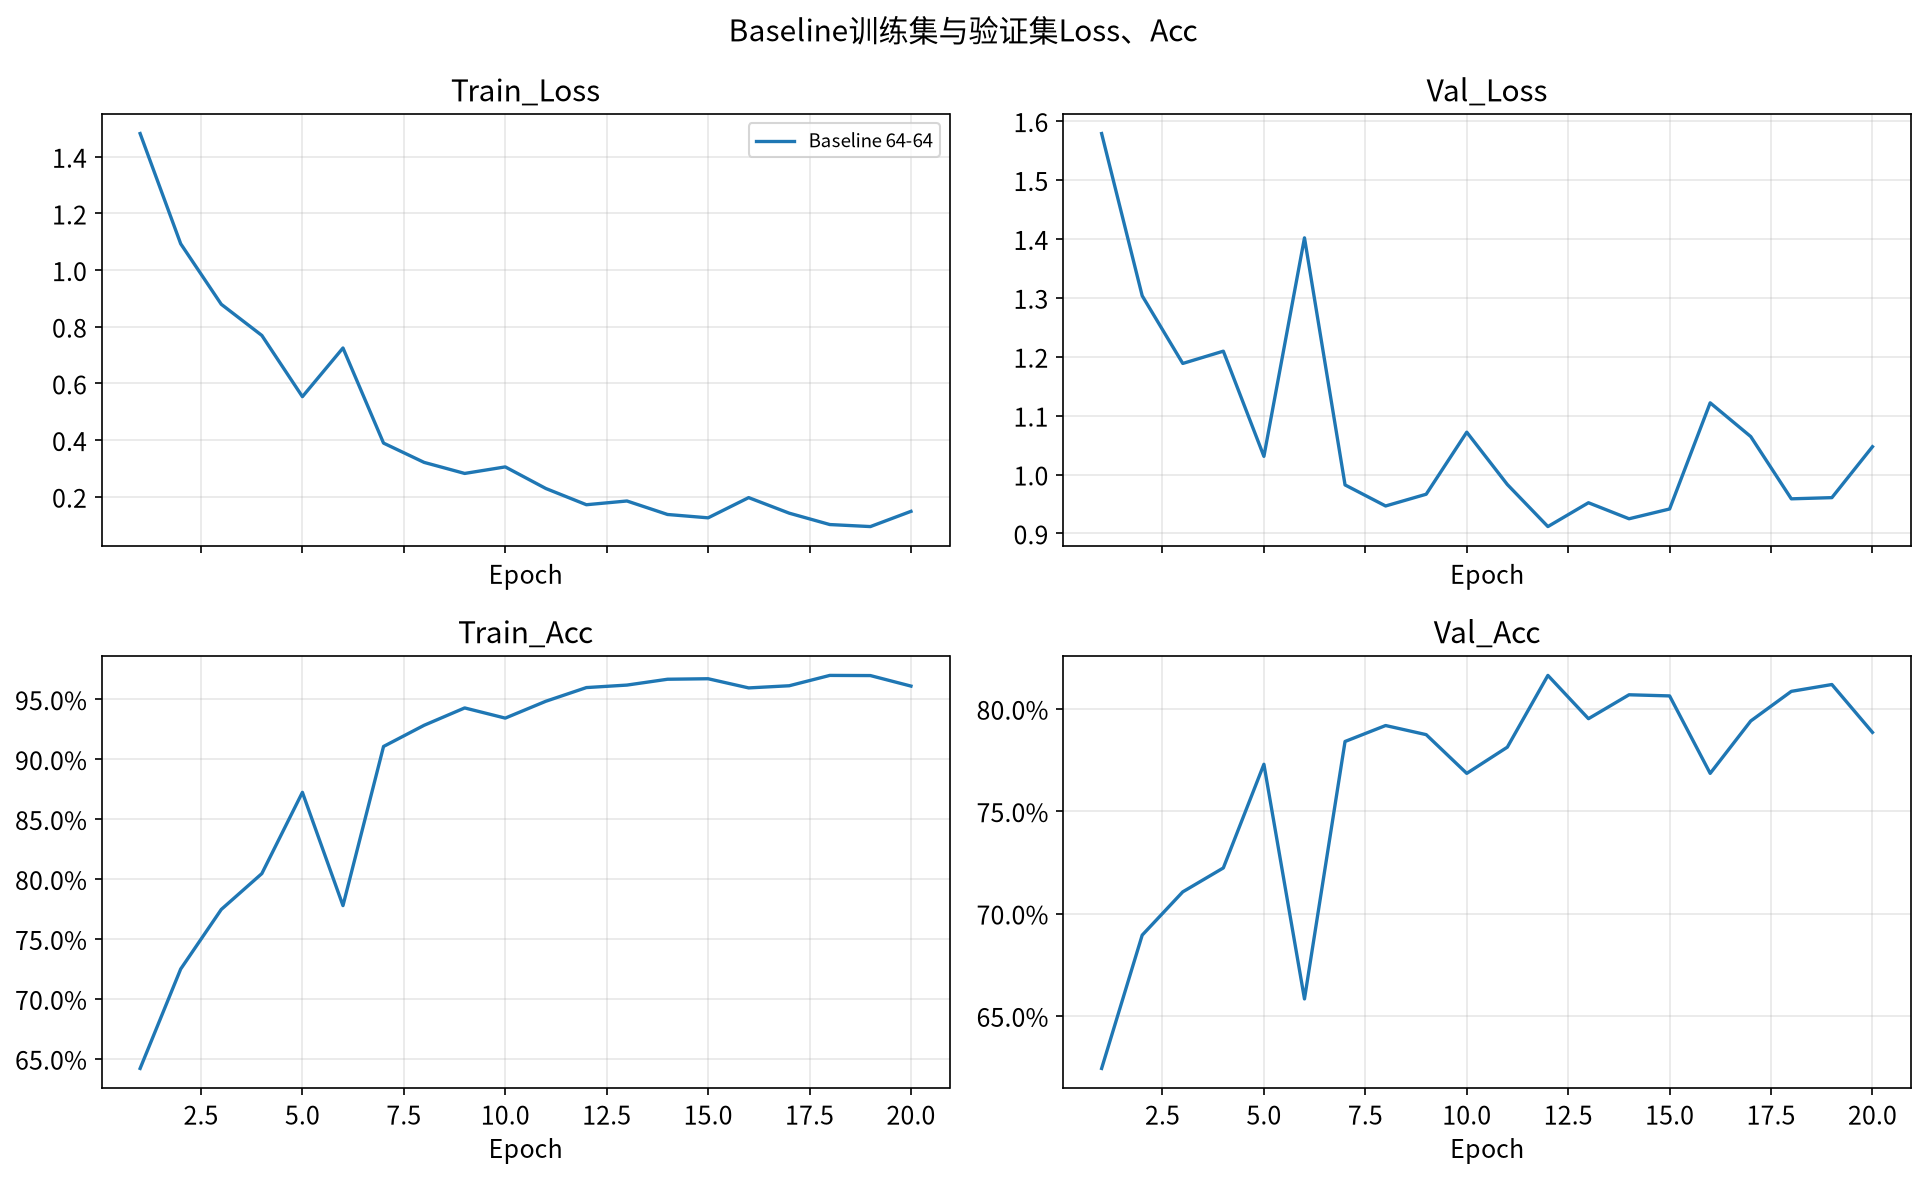

In [16]:
plot_multiple_models_train_result({'Baseline 64-64': train_result_df},
                                 'Baseline训练集与验证集Loss、Acc')

#### 二、参数调整与对比
##### 2.1 隐藏层数
（1）只改变隐藏层数，比较1层、2层（Baseline）和3层，每层均为64单元，其他参数不变。

layers_1: 训练20轮，最佳轮次12；达到最大训练轮次


layers_3: 训练20轮，最佳轮次8；达到最大训练轮次


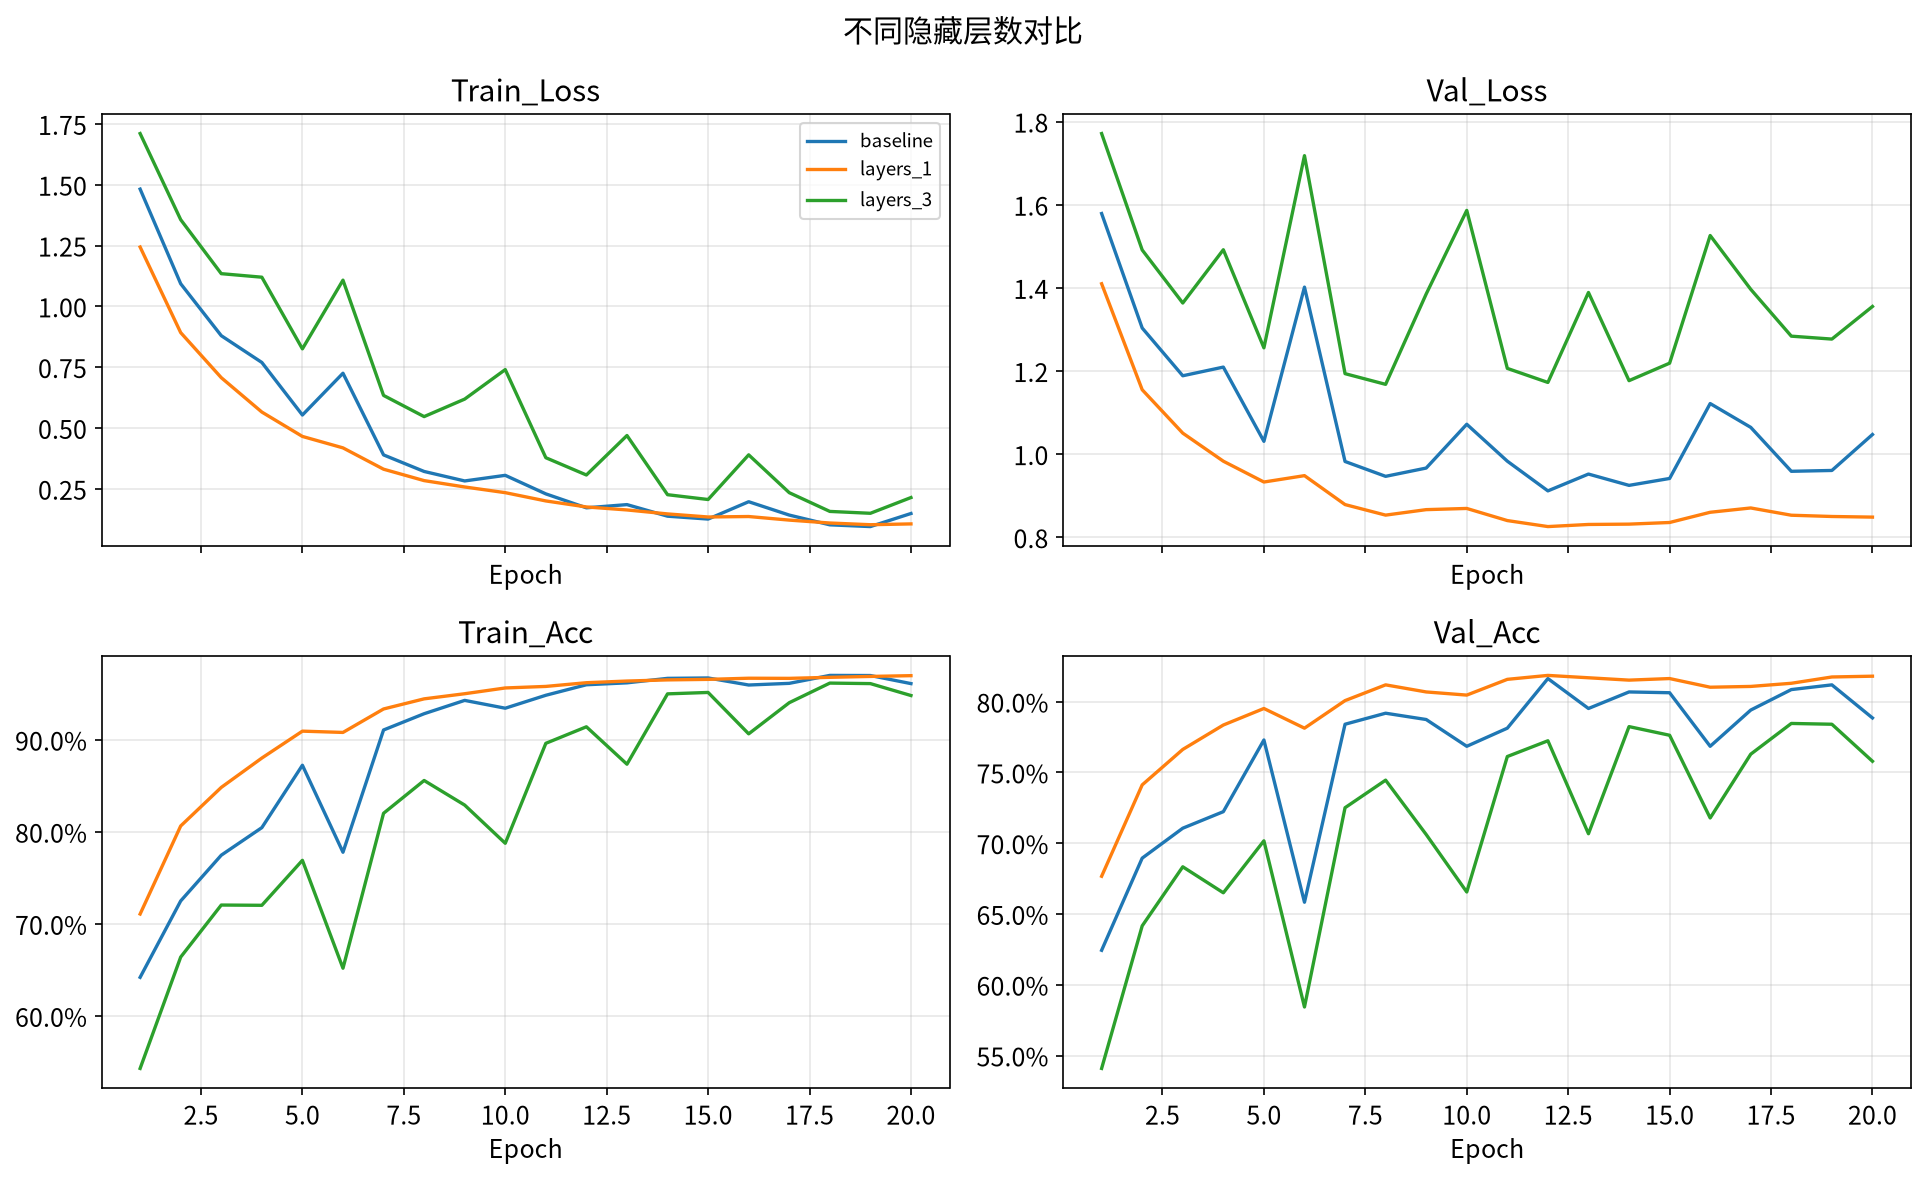

In [17]:
run_experiment('layers_1', hidden_layers=1)
run_experiment('layers_3', hidden_layers=3)
plot_multiple_models_train_result(
    {name: experiments[name]['history'] for name in ['baseline', 'layers_1', 'layers_3']},
    '不同隐藏层数对比')

验证集与测试集结果对比（均为最佳验证Loss检查点）：

| 配置 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :---: | :---: | :---: | :---: |
| baseline | 0.9117 | 81.64% | 1.0446 | 78.45% |
| layers_1 | 0.8258 | 81.86% | 0.9065 | 79.96% |
| layers_3 | 1.1680 | 74.46% | 1.2797 | 72.71% |

结论：本次1层网络的验证Loss最低；增加到3层没有带来更高的验证或测试Acc。

##### 2.2 隐藏层神经元（单元）数
（1）保持2个隐藏层，将每层单元数分别设置为32、64（Baseline）、128。

units_32: 训练20轮，最佳轮次14；达到最大训练轮次


units_128: 训练20轮，最佳轮次9；达到最大训练轮次


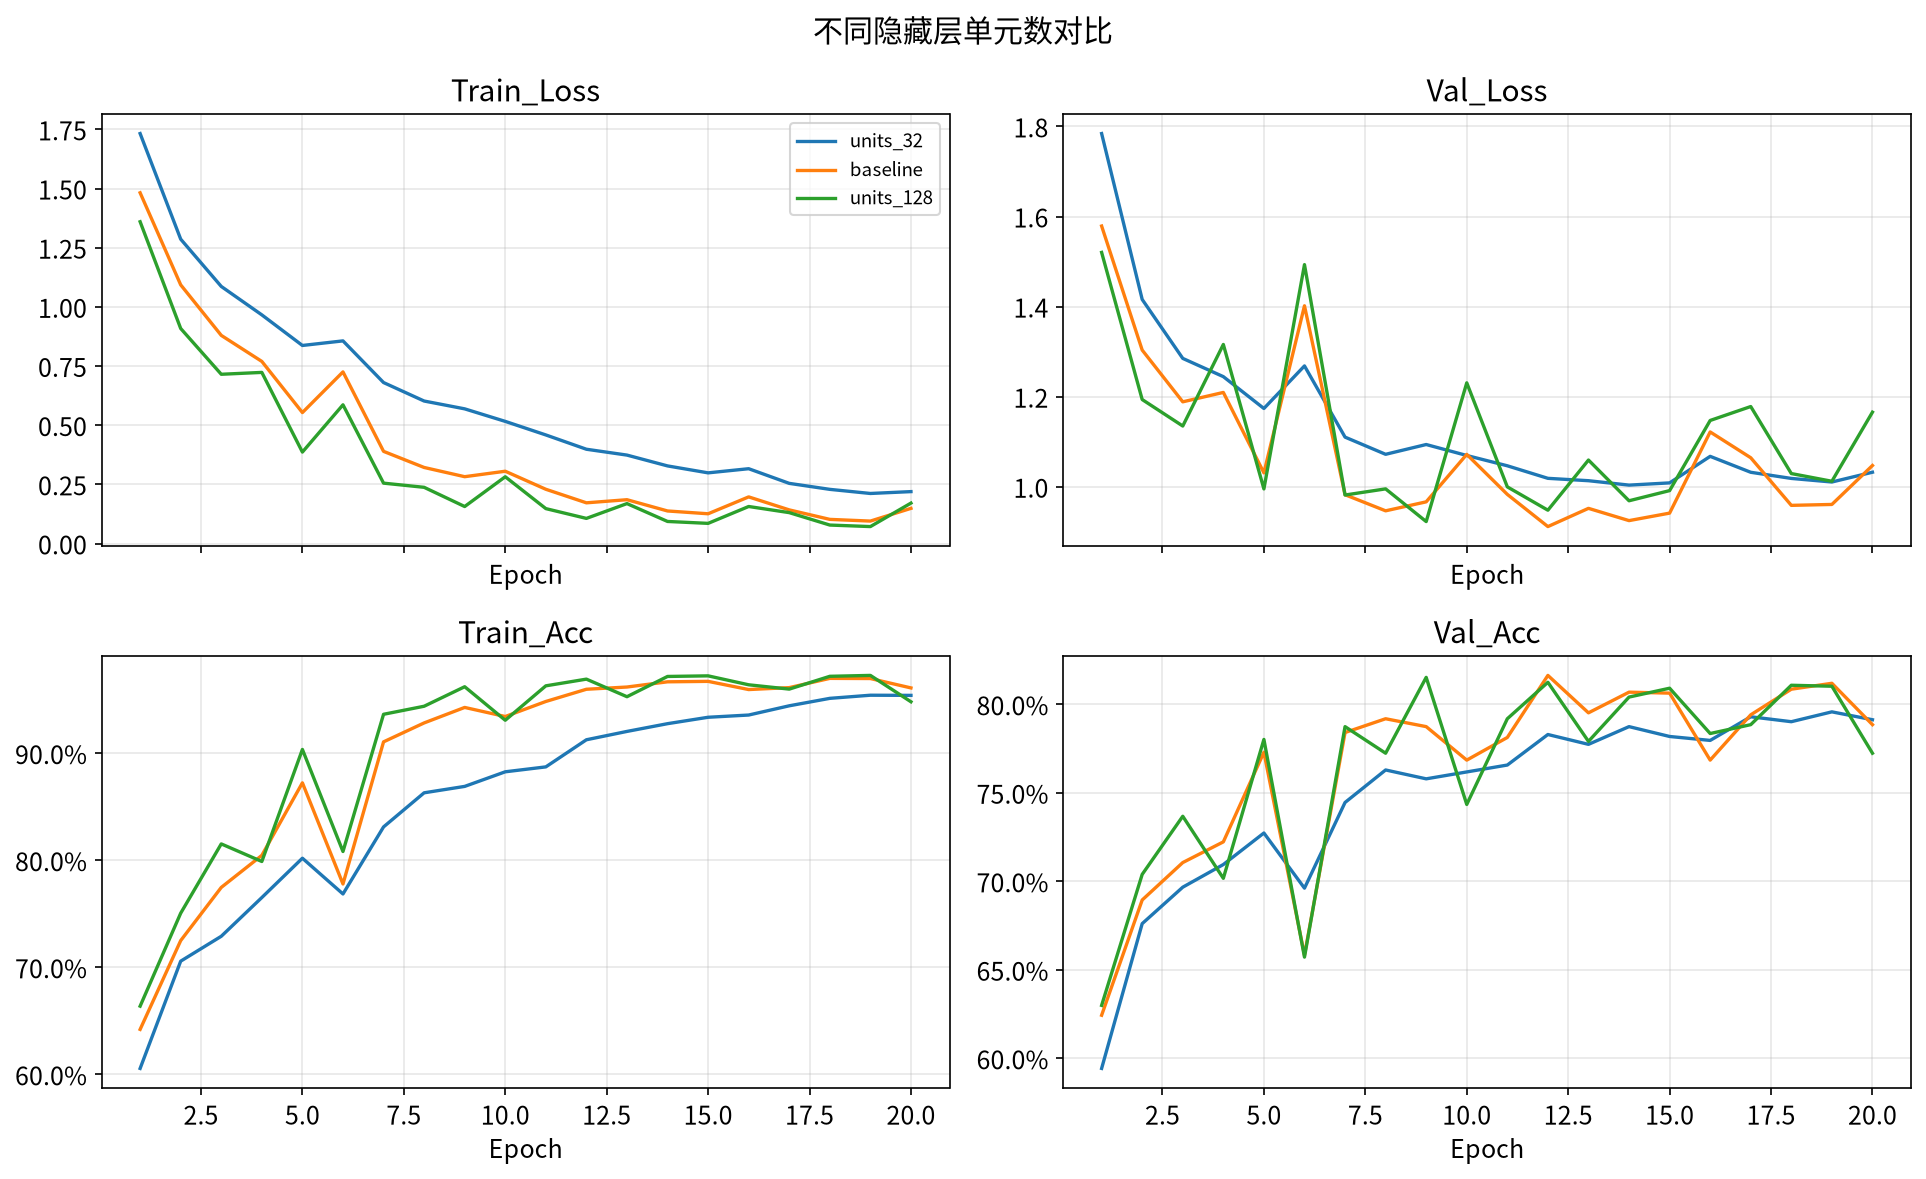

In [18]:
run_experiment('units_32', hidden_num=32)
run_experiment('units_128', hidden_num=128)
plot_multiple_models_train_result(
    {name: experiments[name]['history'] for name in ['units_32', 'baseline', 'units_128']},
    '不同隐藏层单元数对比')

验证集与测试集结果对比（均为最佳验证Loss检查点）：

| 配置 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :---: | :---: | :---: | :---: |
| units_32 | 1.0038 | 78.74% | 1.0764 | 77.25% |
| baseline | 0.9117 | 81.64% | 1.0446 | 78.45% |
| units_128 | 0.9228 | 81.52% | 1.0358 | 78.18% |

结论：固定2层时，32单元的验证Loss较高；64单元比128单元的验证Loss更低，增加宽度并未持续改善泛化。

##### 2.3 批次大小batch
（1）固定64-64网络与20轮上限，将batch设置为128、256、512（Baseline）。小batch每轮更新次数更多，因此训练轮次相同并不等于优化步数相同。

batch_128: 训练20轮，最佳轮次7；达到最大训练轮次


batch_256: 训练20轮，最佳轮次9；达到最大训练轮次


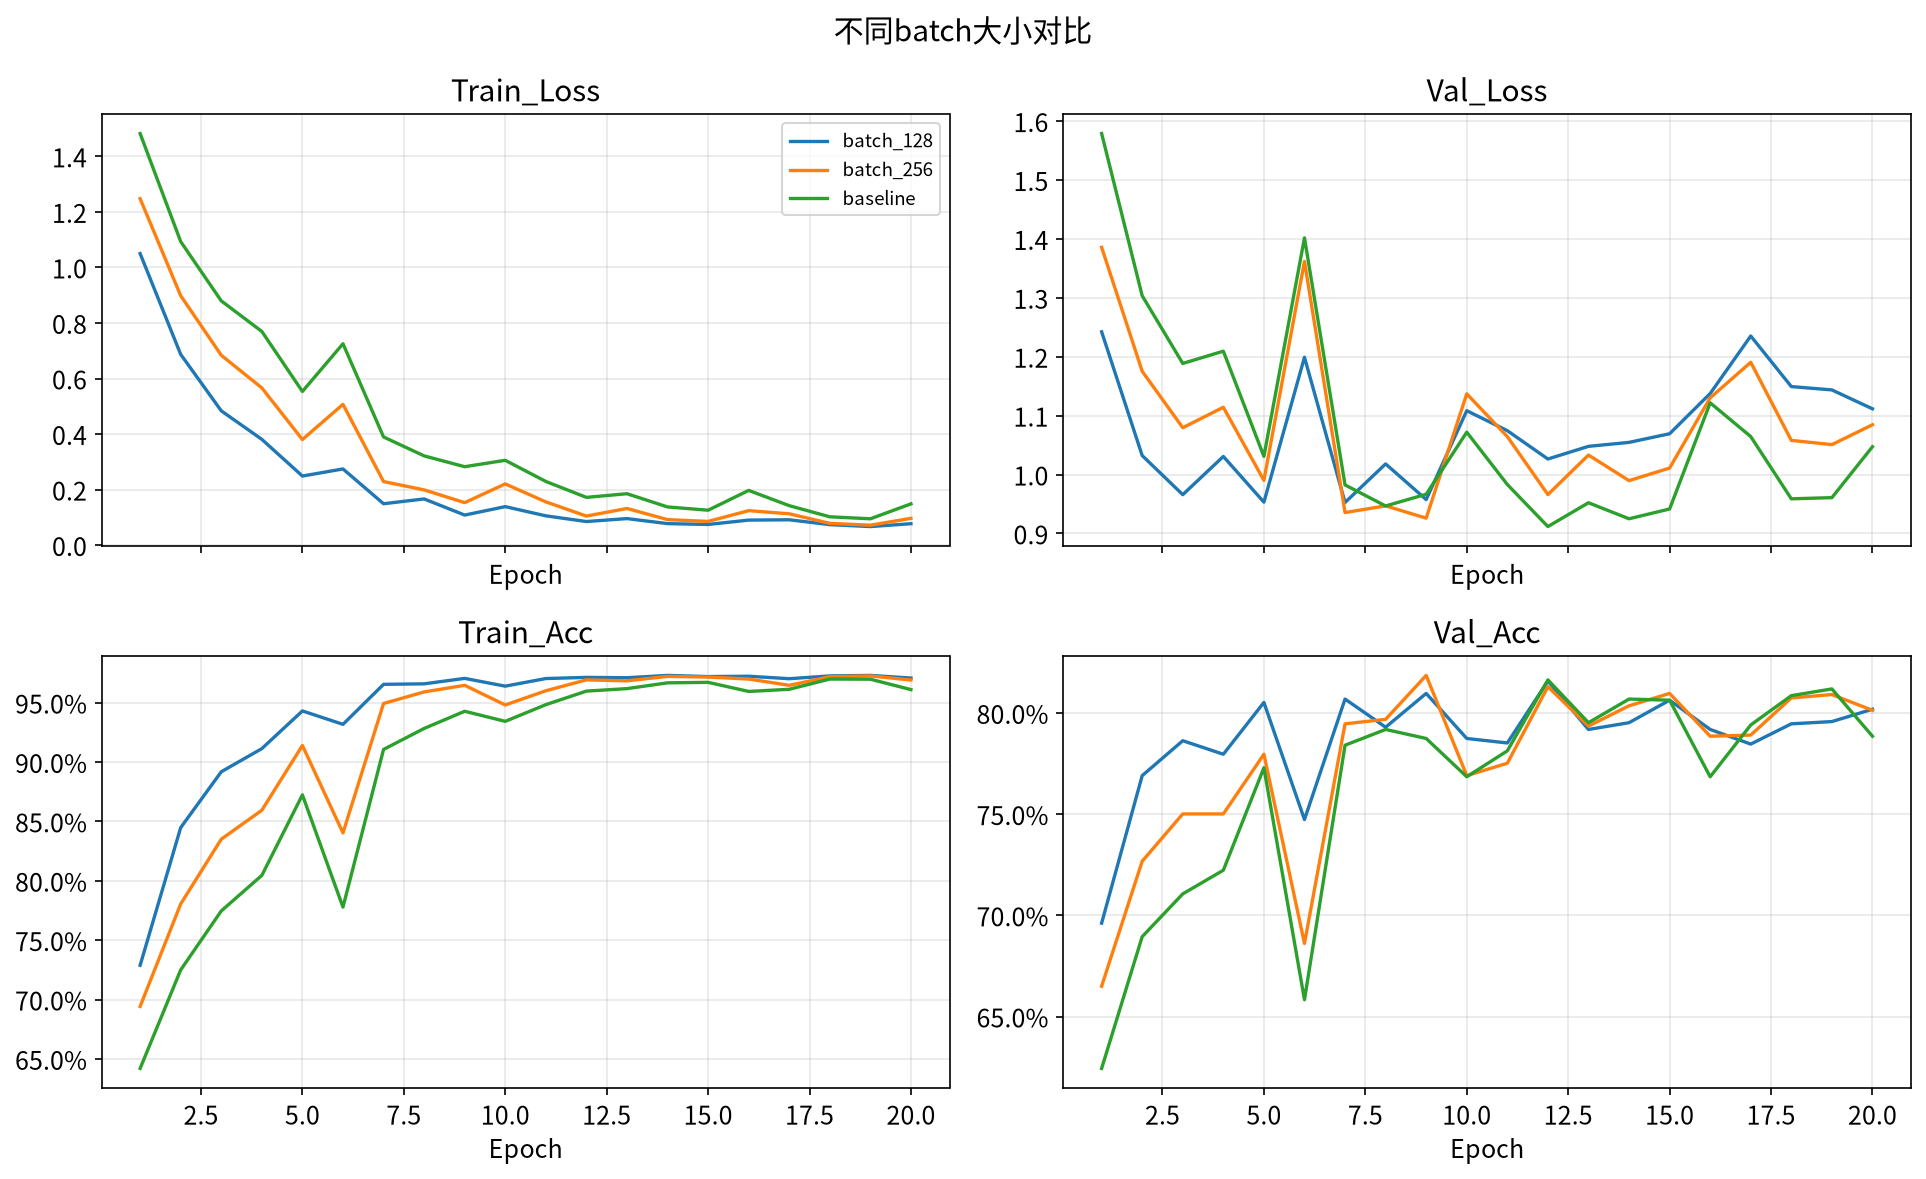

In [19]:
run_experiment('batch_128', batch=128)
run_experiment('batch_256', batch=256)
plot_multiple_models_train_result(
    {name: experiments[name]['history'] for name in ['batch_128', 'batch_256', 'baseline']},
    '不同batch大小对比')

验证集与测试集结果对比（均为最佳验证Loss检查点）：

| 配置 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :---: | :---: | :---: | :---: |
| batch_128 | 0.9526 | 80.69% | 1.0751 | 78.63% |
| batch_256 | 0.9260 | 81.86% | 1.0361 | 78.94% |
| baseline | 0.9117 | 81.64% | 1.0446 | 78.45% |

结论：本组batch=512的验证Loss最低；256的验证Acc略高，表明不同选择指标可能得到不同排序。

##### 2.4 验证精度阈值、过拟合早停与保存最佳模型
（1）分别演示：验证Acc达到75%后停止；验证Loss连续3轮无改善后停止。保存/恢复始终以最低验证Loss为准，达到精度阈值时的最后一轮不一定是最佳轮次。

stop_at_acc: 训练5轮，最佳轮次5；验证Acc达到阈值75%


early_stopping: 训练11轮，最佳轮次8；验证Loss连续3轮未改善，早停


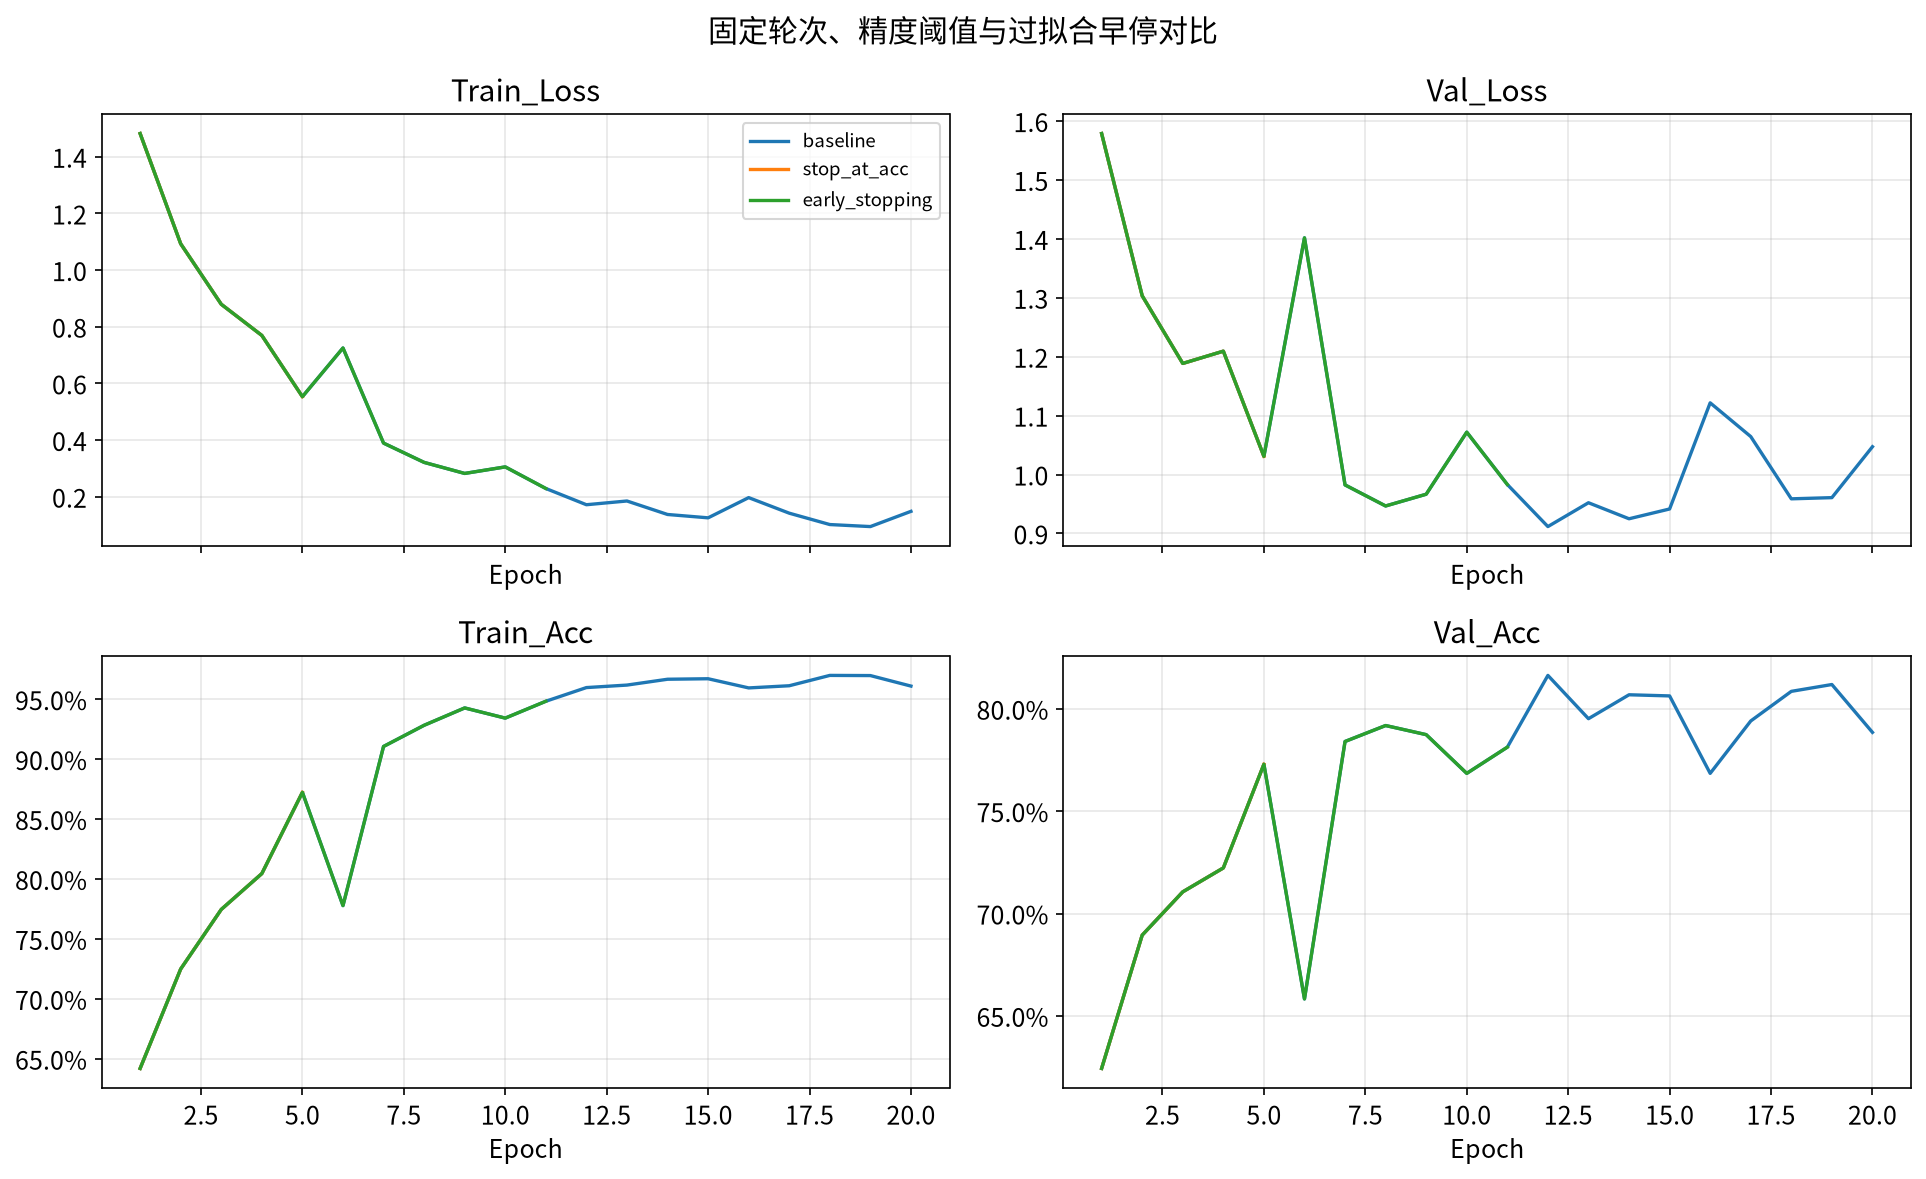

In [20]:
run_experiment('stop_at_acc', epochs=50, target_acc=0.75)
run_experiment('early_stopping', epochs=50, patience=3)
plot_multiple_models_train_result(
    {name: experiments[name]['history'] for name in ['baseline', 'stop_at_acc', 'early_stopping']},
    '固定轮次、精度阈值与过拟合早停对比')

验证集与测试集结果对比（均为最佳验证Loss检查点）：

| 配置 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :---: | :---: | :---: | :---: |
| baseline | 0.9117 | 81.64% | 1.0446 | 78.45% |
| stop_at_acc | 1.0309 | 77.30% | 1.0807 | 75.16% |
| early_stopping | 0.9467 | 79.19% | 1.0309 | 77.60% |

结论：阈值停止与过拟合早停都减少了训练轮次；patience过小也可能错过后续改善。最佳检查点始终按验证Loss保存。

##### 2.5 汇总参数实验并固定最终配置
（1）先按验证Loss选模型，验证Acc作为并列时的第二排序指标。各实验指标均对应已经恢复的最佳检查点。选定后才统一计算测试结果，以满足作业的验证精度、测试精度对比要求。

In [21]:
rows = []
for name, exp in experiments.items():
    rows.append({'Experiment': name, **exp['config'],
                 **exp['info'], 'Val_Loss': exp['val']['Loss'],
                 'Val_Acc': exp['val']['Acc']})
validation_table = pd.DataFrame(rows).sort_values(['Val_Loss', 'Val_Acc'], ascending=[True, False])
best_name = validation_table.iloc[0]['Experiment']
best_model = experiments[best_name]['model']
print('只根据验证集确定的最终配置：', best_name)
display(validation_table.drop(columns='Checkpoint').style.format(
    {'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Seconds': '{:.1f}'}).hide(axis='index'))

只根据验证集确定的最终配置： layers_1


Experiment,hidden_num,hidden_layers,batch,dropout,Best_Epoch,Actual_Epochs,Stop_Reason,Seconds,Val_Loss,Val_Acc
layers_1,64,1,512,0.000000,12,20,达到最大训练轮次,3.2,0.8258,81.86%
baseline,64,2,512,0.000000,12,20,达到最大训练轮次,3.3,0.9117,81.64%
units_128,128,2,512,0.000000,9,20,达到最大训练轮次,3.1,0.9228,81.52%
batch_256,64,2,256,0.000000,9,20,达到最大训练轮次,2.9,0.9260,81.86%
early_stopping,64,2,512,0.000000,8,11,验证Loss连续3轮未改善，早停,1.7,0.9467,79.19%
batch_128,64,2,128,0.000000,7,20,达到最大训练轮次,3.3,0.9526,80.69%
units_32,32,2,512,0.000000,14,20,达到最大训练轮次,3.2,1.0038,78.74%
stop_at_acc,64,2,512,0.000000,5,5,验证Acc达到阈值75%,0.7,1.0309,77.30%
layers_3,64,3,512,0.000000,8,20,达到最大训练轮次,3.2,1.1680,74.46%


In [22]:
test_rows = []
for name, exp in experiments.items():
    result = evaluate_loader(exp['model'], make_loader(x_test, y_test, 512))
    exp['test'] = result
    test_rows.append({'Experiment': name, 'Test_Loss': result['Loss'],
                      'Test_Acc': result['Acc'], 'Test_Macro_F1': result['Macro_F1']})
comparison_table = validation_table.merge(pd.DataFrame(test_rows), on='Experiment')
comparison_table.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
display(comparison_table[['Experiment', 'Val_Loss', 'Val_Acc', 'Test_Loss', 'Test_Acc',
                          'Test_Macro_F1']].style.format(
    {k: ('{:.2%}' if 'Acc' in k else '{:.4f}') for k in
     ['Val_Loss', 'Val_Acc', 'Test_Loss', 'Test_Acc', 'Test_Macro_F1']}).hide(axis='index'))

Experiment,Val_Loss,Val_Acc,Test_Loss,Test_Acc,Test_Macro_F1
layers_1,0.8258,81.86%,0.9065,79.96%,0.5348
baseline,0.9117,81.64%,1.0446,78.45%,0.4501
units_128,0.9228,81.52%,1.0358,78.18%,0.4585
batch_256,0.9260,81.86%,1.0361,78.94%,0.5223
early_stopping,0.9467,79.19%,1.0309,77.60%,0.3726
batch_128,0.9526,80.69%,1.0751,78.63%,0.5263
units_32,1.0038,78.74%,1.0764,77.25%,0.3372
stop_at_acc,1.0309,77.30%,1.0807,75.16%,0.2448
layers_3,1.1680,74.46%,1.2797,72.71%,0.2203


##### 2.6 加载最佳模型并预测
（1）重新创建网络、加载保存的权重，验证恢复前后预测一致，再展示前10条新闻的预测与置信度。

最终测试Loss=0.9065，Acc=79.96%，Macro-F1=0.5348


,真实主题,预测主题,置信度
0,3,3,0.873133
1,10,10,0.845552
2,1,1,0.645547
3,4,4,0.857374
4,4,13,0.985240
5,3,3,0.987207
6,3,3,0.870236
7,3,3,0.992943
8,3,3,0.998282
9,3,3,0.973620


              precision    recall  f1-score   support

           0      0.889     0.667     0.762        12
           1      0.667     0.800     0.727       105
           2      0.824     0.700     0.757        20
           3      0.915     0.941     0.928       813
           4      0.829     0.901     0.863       474
           5      0.000     0.000     0.000         5
           6      1.000     0.929     0.963        14
           7      1.000     0.333     0.500         3
           8      0.684     0.684     0.684        38
           9      0.842     0.640     0.727        25
          10      0.800     0.800     0.800        30
          11      0.596     0.819     0.690        83
          12      0.571     0.308     0.400        13
          13      0.585     0.649     0.615        37
          14      1.000     0.500     0.667         2
          15      0.500     0.111     0.182         9
          16      0.667     0.788     0.722        99
          17      1.000    

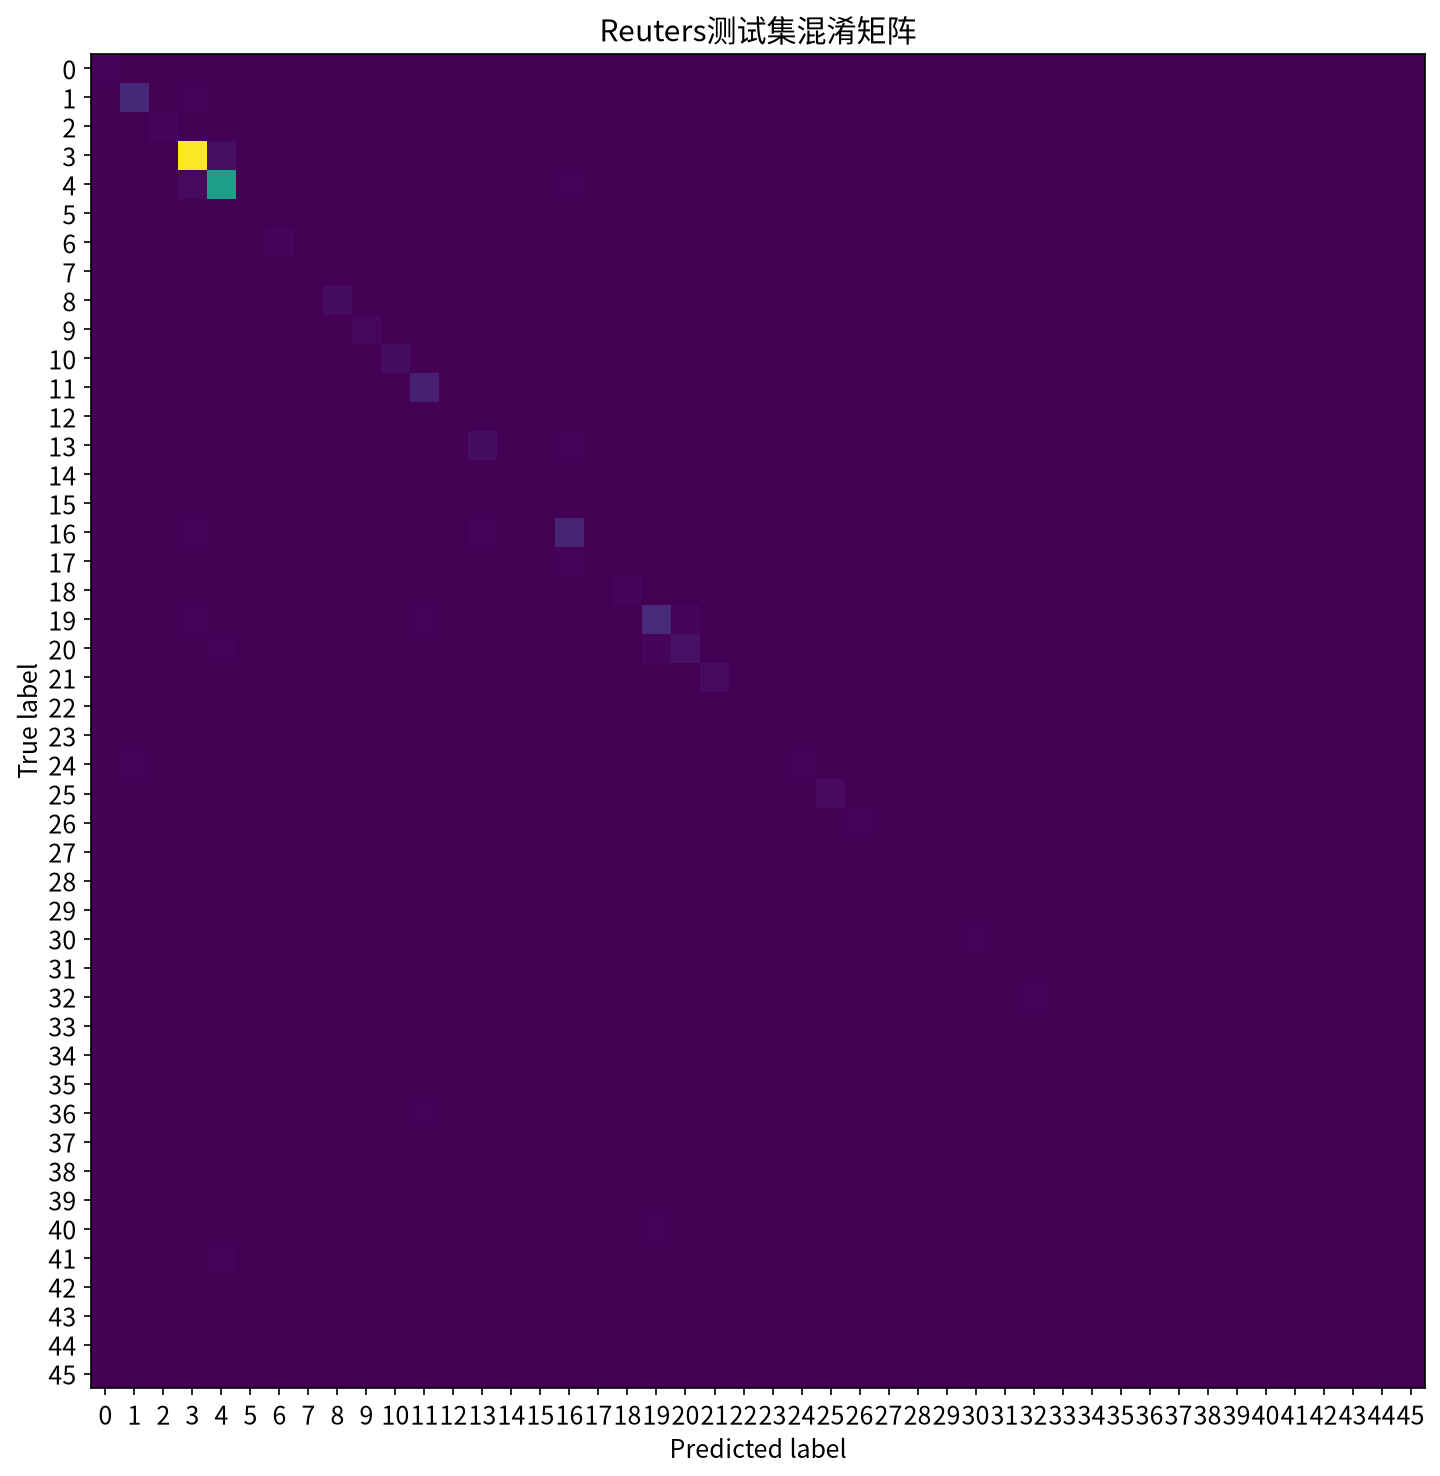

4855

In [23]:
best_exp = experiments[best_name]
cfg = best_exp['config']
restored_model = (Net() if (cfg['hidden_num'], cfg['hidden_layers'], cfg['dropout']) == (64, 2, 0.0)
                  else HiddenNumNet(cfg['hidden_num'], cfg['hidden_layers'], cfg['dropout'])).to(device)
state = torch.load(best_exp['info']['Checkpoint'], map_location=device, weights_only=True)
restored_model.load_state_dict(state['model_state_dict'])
final_result = evaluate_loader(restored_model, make_loader(x_test, y_test, 512))
assert np.array_equal(final_result['y_pred'], best_exp['test']['y_pred'])
print(f"最终测试Loss={final_result['Loss']:.4f}，Acc={final_result['Acc']:.2%}，Macro-F1={final_result['Macro_F1']:.4f}")
prediction_df = pd.DataFrame({'真实主题': y_test[:10],
                              '预测主题': final_result['y_pred'][:10],
                              '置信度': final_result['probabilities'][:10].max(axis=1)})
display(prediction_df)
print(classification_report(y_test, final_result['y_pred'], labels=list(range(46)),
                            zero_division=0, digits=3))
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_test, final_result['y_pred'],
                                        labels=list(range(46)), ax=ax,
                                        include_values=False, colorbar=False)
ax.set_title('Reuters测试集混淆矩阵')
plt.tight_layout()
plt.show()
summary = {'best_name': best_name, 'config': cfg,
           'test': {k: float(final_result[k]) for k in ['Loss', 'Acc', 'Macro_F1']},
           'experiments': comparison_table.to_dict(orient='records')}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

#### 三、TensorBoard结果

**训练与验证指标（Scalars）**

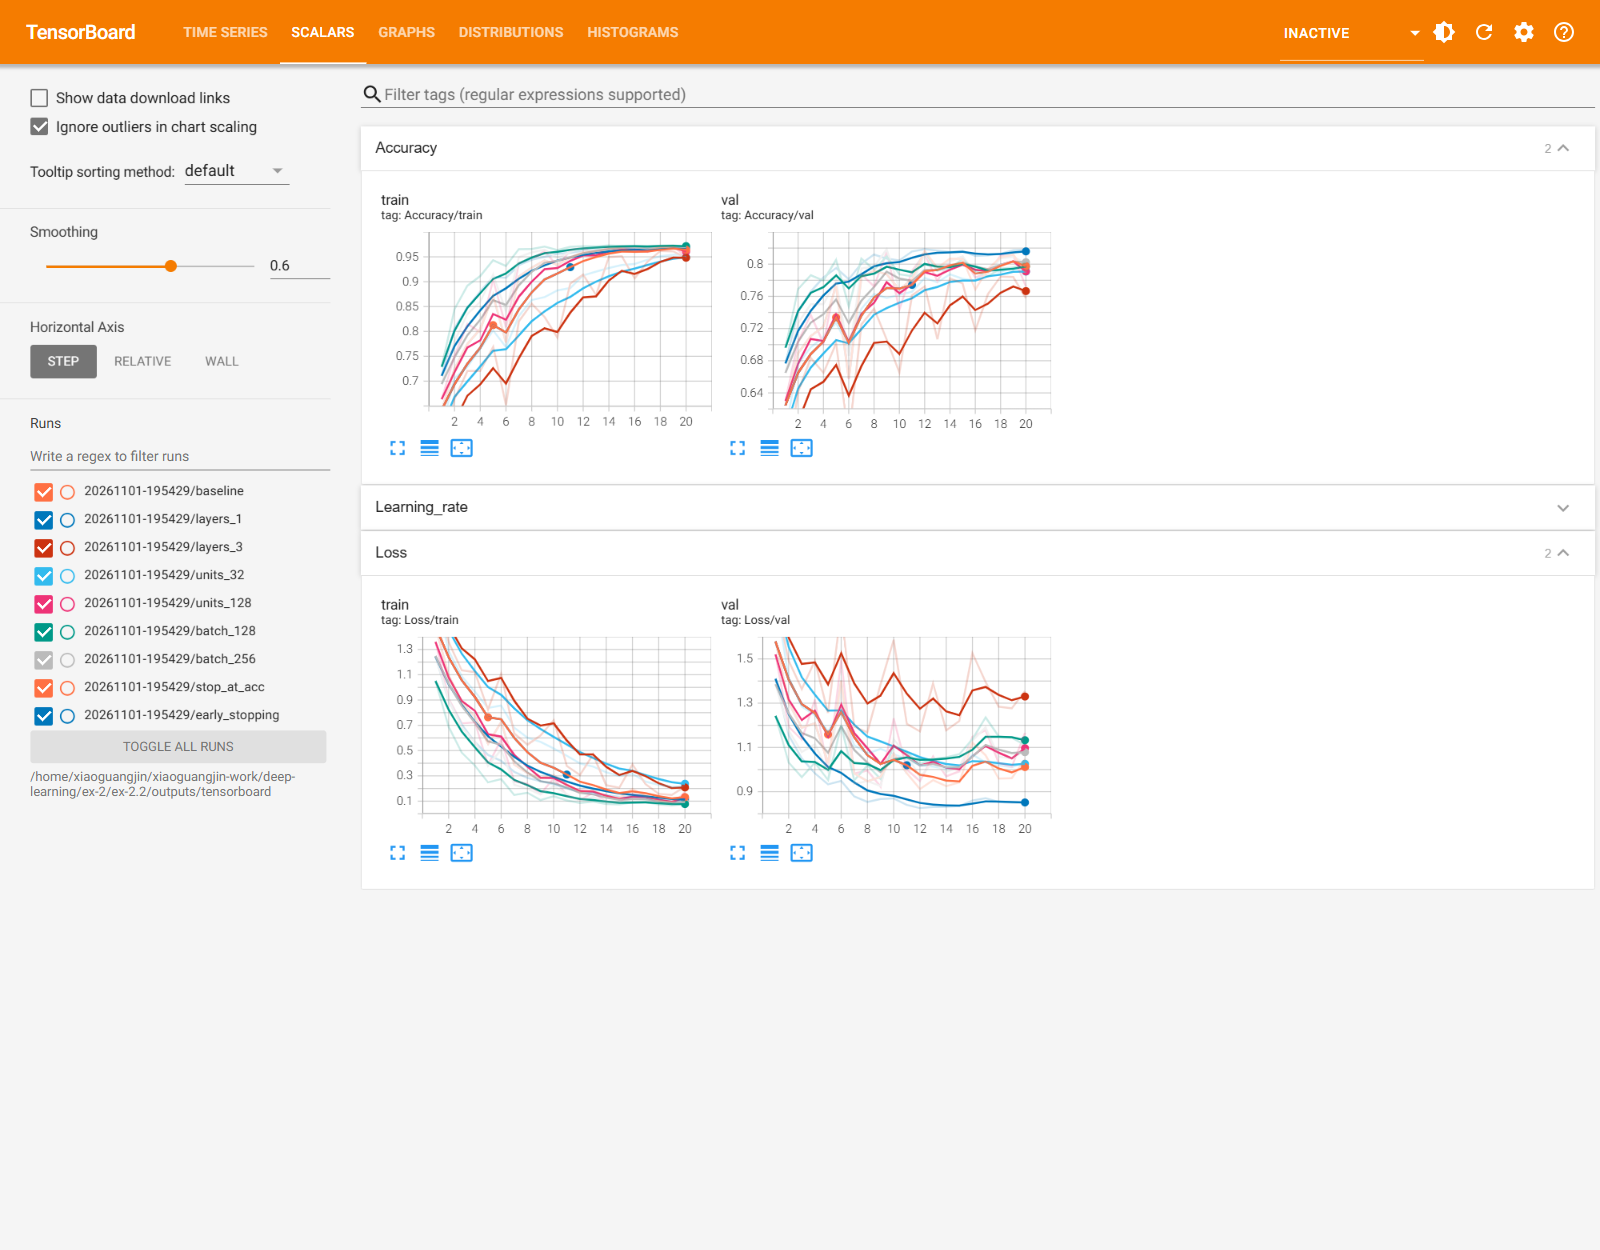

**模型计算图（Graphs）**

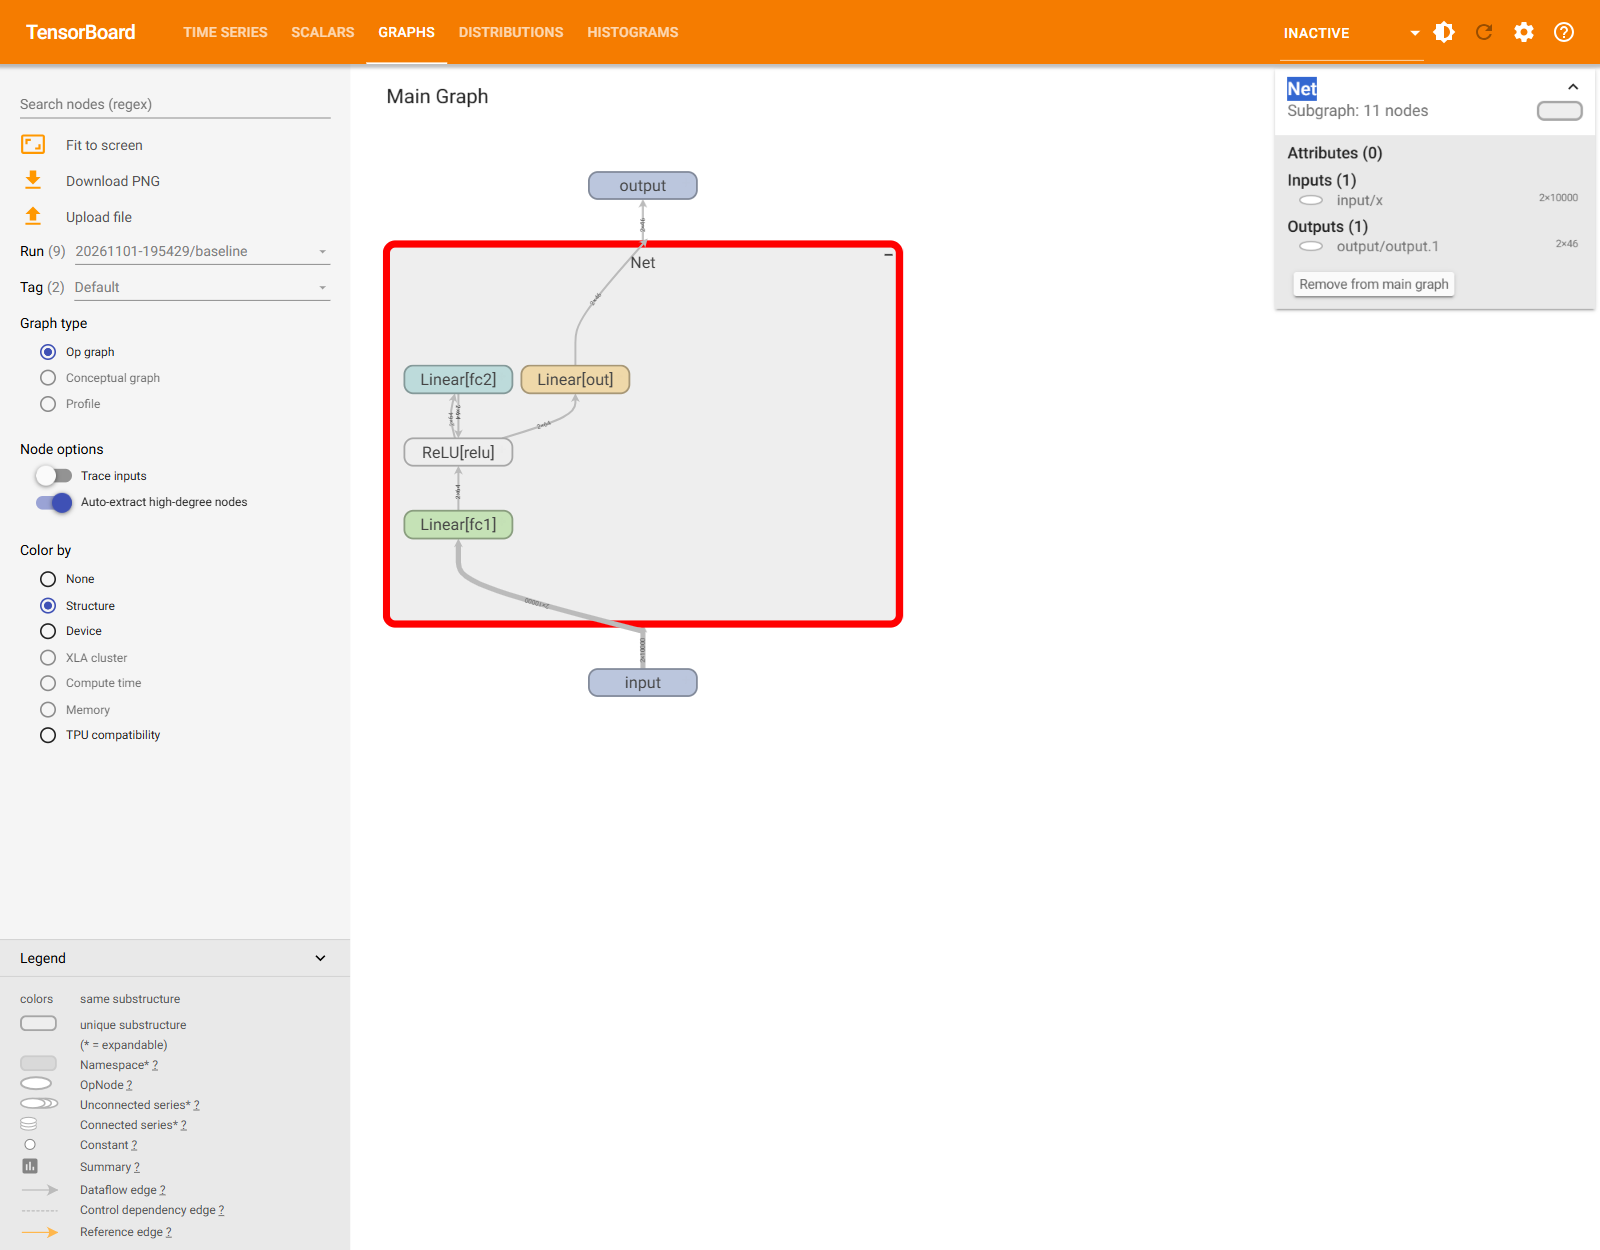



#### 四、结果分析

（1）结果汇总

使用Reuters的8982条原训练新闻和2246条测试新闻，将原训练新闻分层划分为7185条训练、1797条验证；词表10000，主题46类。每组实验从头初始化，使用相同随机种子与数据划分，按验证Loss保存、恢复最佳检查点。

| 配置 | 最佳轮次 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :---: | :---: | :---: | :---: | :---: |
| baseline | 12 | 0.9117 | 81.64% | 1.0446 | 78.45% |
| layers_1 | 12 | 0.8258 | 81.86% | 0.9065 | 79.96% |
| layers_3 | 8 | 1.1680 | 74.46% | 1.2797 | 72.71% |
| units_32 | 14 | 1.0038 | 78.74% | 1.0764 | 77.25% |
| units_128 | 9 | 0.9228 | 81.52% | 1.0358 | 78.18% |
| batch_128 | 7 | 0.9526 | 80.69% | 1.0751 | 78.63% |
| batch_256 | 9 | 0.9260 | 81.86% | 1.0361 | 78.94% |
| stop_at_acc | 5 | 1.0309 | 77.30% | 1.0807 | 75.16% |
| early_stopping | 8 | 0.9467 | 79.19% | 1.0309 | 77.60% |

（2）隐藏层数的影响

Baseline为64-64网络，测试Acc为78.45%。单层64单元的验证Loss最低（0.8258），测试Acc为79.96%；三层64单元测试Acc为72.71%。本次固定优化器与轮次设置下，增加深度没有改善结果，较浅模型已能提取有效词项信息。不能据此推断所有文本任务都应选单层网络。

（3）隐藏单元数与batch的影响

2层网络中，32、64、128单元测试Acc依次为77.25%、78.45%、78.18%。32单元存在表示容量瓶颈，128单元也未稳定提高泛化性能。batch=128、256、512测试Acc依次为78.63%、78.94%、78.45%；batch不是越小或越大越好，还会改变每轮更新次数。

（4）训练监控与模型保存

验证Acc阈值设为75%，在第5轮触发，恢复后验证Acc为77.30%。验证Loss连续3轮无改善的实验在第11轮停止，恢复第8轮权重。早停减少计算，但patience=3可能错过后续改善，因此它是监控策略示例，不保证优于完整20轮中选出的检查点。TensorBoard图中训练与验证曲线的分离用于判断过拟合。

（5）最终模型

按验证Loss确定最终配置为**单隐藏层64单元、batch=512、RMSprop、lr=0.001**，恢复第12轮权重；最终测试Loss为0.9065，Acc为**79.96%**，Macro-F1为0.5348。所有测试指标在配置固定后统一计算，不依据测试结果反向改参数。保存模型重新加载后的预测已与原模型逐项核对一致。

总体Acc明显高于Macro-F1，说明类别不平衡时只看Acc会掩盖小类别表现；实际部署还需检查每类召回率并使用更多样的样本验证。
